In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

In [5]:
data = pd.read_csv(r'E:\DigitalentDA\Datasets\diabetes.csv')
df = pd.DataFrame(data)

print(df.head())
print(df.info())
print(df.describe())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null  

In [6]:
X = df.drop(columns=['Outcome'])
y = df['Outcome']

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# stratify=y digunakan agar proporsi kelas 0 dan 1 seimbang di train dan test set

In [8]:
train_score, test_score = [], []
depth_range = range(1, 15)

for depth in depth_range:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)

    train_score.append(model.score(X_train, y_train))
    test_score.append(model.score(X_test, y_test))

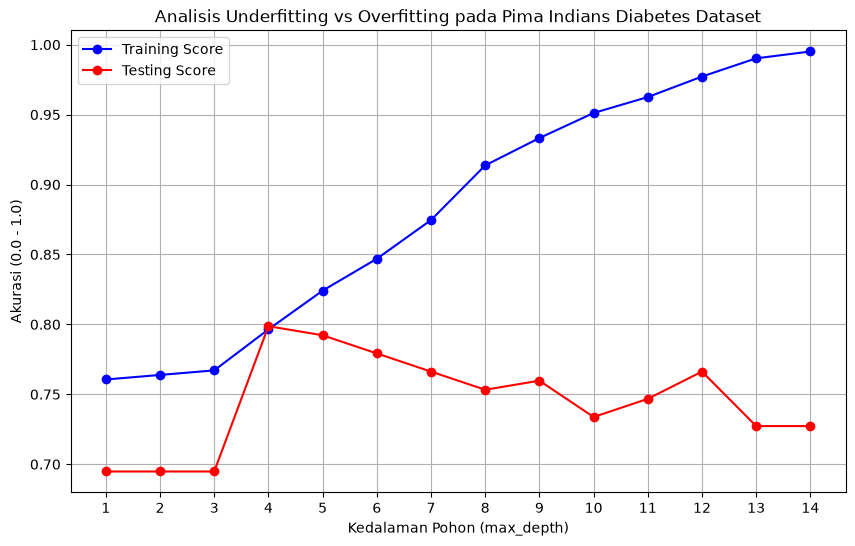

In [9]:
plt.figure(figsize=(10, 6))
plt.plot(depth_range, train_score, "o-", 
         color="blue", label="Training Score")
plt.plot(depth_range, test_score, "o-",
         color="red", label="Testing Score")

plt.xlabel("Kedalaman Pohon (max_depth)")
plt.ylabel("Akurasi (0.0 - 1.0)")
plt.title("Analisis Underfitting vs Overfitting pada Pima Indians Diabetes Dataset")
plt.xticks(depth_range)
plt.legend()
plt.grid(True)
plt.show()
